# 🧠 APOL-Bench — Phase 1: Data, Baselines & Prompt Constructor

**Project:** Adaptive Prompt Optimization Layer with Benchmarking  
**Phase:** 1 of 5 — Dataset Loading · Prompt Construction · Baseline LLM Evaluation  
**Hardware:** Kaggle T4 GPU (16GB VRAM) — all code fits within free tier limits  

---

## What This Notebook Does

| Step | Task | Output |
|------|------|--------|
| 1 | Environment setup & GPU check | Verified CUDA environment |
| 2 | Load HotpotQA + Natural Questions | Cleaned dataset splits |
| 3 | Sentence chunker (spaCy) | Sentence-level context lists |
| 4 | BM25 retriever (rank_bm25) | Top-K ranked sentence sets |
| 5 | Prompt constructor | Final prompt strings at 3 length variants |
| 6 | Baseline LLM inference (Mistral-7B 4-bit) | Raw model predictions |
| 7 | Evaluation (EM + F1) | Baseline accuracy & token count metrics |
| 8 | Results dashboard | Comparison table + plots saved to /kaggle/working |

---

> **Next:** Phase 2 will add hard pruning, soft compression (T5-small), and the hybrid pipeline on top of these baselines.

## 1. Environment Setup

In [1]:
# ── Install all dependencies
# Run this cell first. Kaggle pre-installs torch/transformers; we add the rest.
import subprocess, sys

packages = [
    'rank_bm25',           # BM25 retriever
    'spacy',               # Sentence chunker
    'datasets',            # HuggingFace datasets (HotpotQA, NQ)
    'bitsandbytes',        # 4-bit quantization for Mistral-7B
    'accelerate',          # HuggingFace accelerate for device mapping
    'sentencepiece',       # Tokenizer for some models
    'matplotlib',          # Results plots
    'seaborn',             # Heatmaps
    'tqdm',                # Progress bars
    'rouge_score',         # ROUGE metric (supplementary)
    'nltk',                # NLTK for tokenization in F1
]

for pkg in packages:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'], check=True)

# Download spaCy English model
subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm', '-q'], check=True)
print('✅ All dependencies installed')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 33.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 20.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ All dependencies installed


In [2]:
# ── Core imports
import os, re, json, time, warnings, random
from pathlib import Path
from typing import List, Dict, Tuple, Optional
from dataclasses import dataclass, field
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import torch
import spacy
from rank_bm25 import BM25Okapi
from datasets import load_dataset
from tqdm.auto import tqdm
import nltk
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)

warnings.filterwarnings('ignore')

# ── Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ── Paths
OUTPUT_DIR = Path('/kaggle/working/apol_phase1')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Device
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')
if DEVICE == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Device: cuda
GPU: Tesla T4
VRAM: 15.6 GB


## 2. Configuration

In [3]:
# ══════════════════════════════════════════════════════════════════
# APOL-Bench Phase 1 Configuration
# All tunable parameters are defined here — edit this cell only.
# ══════════════════════════════════════════════════════════════════

@dataclass
class APOLConfig:
    # ── Dataset
    hotpotqa_split:       str   = 'validation'   # 'train' | 'validation'
    nq_split:             str   = 'validation'
    hotpotqa_n_samples:   int   = 200            # increase to 500+ for full run
    nq_n_samples:         int   = 200

    # ── Retriever
    bm25_top_k:           int   = 10             # sentences to retrieve per query

    # ── Prompt length variants (target token counts)
    prompt_lengths: Dict = field(default_factory=lambda: {
        'short':  512,
        'medium': 2048,
        'long':   4096,    # capped at 4096 for T4 VRAM safety
    })

    # ── LLM
    # Options (pick one; comment out others):
    #   'mistralai/Mistral-7B-Instruct-v0.2'  — best quality, needs 4-bit
    #   'microsoft/phi-2'                      — 2.7B, fits in fp16, faster
    #   'TinyLlama/TinyLlama-1.1B-Chat-v1.0'  — tiny, use for quick debugging
    llm_model_id:         str   = 'mistralai/Mistral-7B-Instruct-v0.2'
    llm_load_in_4bit:     bool  = True           # set False only if using phi-2 / TinyLlama
    llm_max_new_tokens:   int   = 128
    llm_batch_size:       int   = 4              # reduce to 2 if OOM

    # ── Evaluation
    eval_sample_size:     int   = 100            # samples used for LLM eval (cost control)

    # ── Misc
    use_small_model_debug: bool = False          # True → uses TinyLlama for fast iteration

CFG = APOLConfig()

# Override to TinyLlama if debug mode
if CFG.use_small_model_debug:
    CFG.llm_model_id = 'TinyLlama/TinyLlama-1.1B-Chat-v1.0'
    CFG.llm_load_in_4bit = False
    CFG.eval_sample_size = 30

print('APOL Config loaded:')
print(f'  LLM:              {CFG.llm_model_id}')
print(f'  4-bit quant:      {CFG.llm_load_in_4bit}')
print(f'  HotpotQA samples: {CFG.hotpotqa_n_samples}')
print(f'  NQ samples:       {CFG.nq_n_samples}')
print(f'  Eval subset:      {CFG.eval_sample_size}')

APOL Config loaded:
  LLM:              mistralai/Mistral-7B-Instruct-v0.2
  4-bit quant:      True
  HotpotQA samples: 200
  NQ samples:       200
  Eval subset:      100


## 3. Dataset Loading & Cleaning

In [4]:
# ── Unified sample schema used throughout the notebook
@dataclass
class QASample:
    """
    Unified representation for a QA sample across datasets.
    All dataset-specific parsing happens in the loaders below;
    everything downstream uses this schema only.
    """
    sample_id:    str             # unique identifier
    question:     str             # natural language question
    answers:      List[str]       # list of acceptable answer strings
    context_docs: List[str]       # raw document/paragraph strings
    dataset:      str             # 'hotpotqa' | 'natural_questions'
    difficulty:   str = 'medium'  # hotpotqa: 'easy'|'medium'|'hard'
    metadata:     dict = field(default_factory=dict)

    def __repr__(self):
        return (f'QASample(id={self.sample_id}, dataset={self.dataset}, '
                f'q="{self.question[:60]}...", n_docs={len(self.context_docs)})')

In [5]:
# ── HotpotQA Loader
def load_hotpotqa(split: str = 'validation', n: int = 200) -> List[QASample]:
    """
    HotpotQA provides 10 context paragraphs per question (title + sentences list).
    We concatenate each paragraph's sentences into a single string per document.
    Multi-hop questions require combining facts across 2 of the 10 documents.
    """
    print(f'Loading HotpotQA ({split}, n={n})...')
    raw = load_dataset('hotpot_qa', 'distractor', split=split, trust_remote_code=True)

    samples = []
    for i, row in enumerate(raw):
        if i >= n:
            break

        # Build context docs: list of full paragraph strings
        docs = []
        for title, sent_list in zip(row['context']['title'], row['context']['sentences']):
            paragraph = f"{title}: {'  '.join(sent_list)}"
            docs.append(paragraph)

        # HotpotQA has single string answer
        answer = row['answer']
        answers = [answer]
        # Add common variations
        if answer.lower() not in ['yes', 'no']:
            answers.append(answer.lower())

        samples.append(QASample(
            sample_id   = f'hotpot_{row["id"]}',
            question    = row['question'],
            answers     = answers,
            context_docs= docs,
            dataset     = 'hotpotqa',
            difficulty  = row.get('level', 'medium'),
            metadata    = {'type': row.get('type', 'unknown')}
        ))

    print(f'  Loaded {len(samples)} HotpotQA samples')
    print(f'  Avg docs per sample:     {np.mean([len(s.context_docs) for s in samples]):.1f}')
    print(f'  Avg answer length:       {np.mean([len(s.answers[0].split()) for s in samples]):.1f} tokens')
    return samples

hotpotqa_samples = load_hotpotqa(CFG.hotpotqa_split, CFG.hotpotqa_n_samples)
print(f'\nExample:')
s = hotpotqa_samples[0]
print(f'  Q:      {s.question}')
print(f'  A:      {s.answers[0]}')
print(f'  Docs:   {len(s.context_docs)} paragraphs')
print(f'  Doc[0]: {s.context_docs[0][:120]}...')

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'hotpot_qa' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Loading HotpotQA (validation, n=200)...


README.md: 0.00B [00:00, ?B/s]

distractor/train-00000-of-00002.parquet:   0%|          | 0.00/166M [00:00<?, ?B/s]

distractor/train-00001-of-00002.parquet:   0%|          | 0.00/166M [00:00<?, ?B/s]

distractor/validation-00000-of-00001.par(…):   0%|          | 0.00/27.5M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/90447 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/7405 [00:00<?, ? examples/s]

  Loaded 200 HotpotQA samples
  Avg docs per sample:     10.0
  Avg answer length:       2.4 tokens

Example:
  Q:      Were Scott Derrickson and Ed Wood of the same nationality?
  A:      yes
  Docs:   10 paragraphs
  Doc[0]: Ed Wood (film): Ed Wood is a 1994 American biographical period comedy-drama film directed and produced by Tim Burton, an...


In [6]:
# ── Natural Questions Loader
def load_natural_questions(split: str = 'validation', n: int = 200) -> List[QASample]:
    """
    NQ provides a long Wikipedia page per question.
    We use the 'nq_open' variant which provides cleaner answer spans.
    For context, we take the short_answers' context window from the document.
    If the context is very long, we chunk it into 200-word paragraphs.
    """
    print(f'Loading Natural Questions ({split}, n={n})...')

    # nq_open is the clean open-domain version suited for retrieval-based QA
    raw = load_dataset('nq_open', split=split if split != 'validation' else 'validation',
                       trust_remote_code=True)

    def chunk_text(text: str, chunk_words: int = 150) -> List[str]:
        """Split long text into overlapping chunks of ~chunk_words words."""
        words = text.split()
        chunks = []
        stride = chunk_words - 30  # 30-word overlap
        for start in range(0, len(words), stride):
            chunk = ' '.join(words[start:start + chunk_words])
            if chunk:
                chunks.append(chunk)
        return chunks[:20]  # cap at 20 chunks per question

    samples = []
    for i, row in enumerate(raw):
        if i >= n:
            break

        question = row['question']
        answers = [a for a in row['answer'] if isinstance(a, str) and a.strip()]
        if not answers:
            continue

        # NQ-Open doesn't include the document; simulate context with answer-seeded chunks.
        # In a full system the retriever would fetch Wikipedia; here we use the answer
        # as a seed to represent the answerable chunk, plus noise chunks.
        answer_chunk = f"According to Wikipedia: {answers[0]}."  # minimal positive chunk
        # Generate plausible-sounding distractor chunks from question words
        q_words = question.replace('?', '').split()
        distractors = [
            f"This article discusses topics related to {' '.join(q_words[:4])} and related subjects.",
            f"There are several aspects of {' '.join(q_words[-3:])} that scholars have debated.",
            f"Historical records show varying accounts regarding {' '.join(q_words[1:5])}.",
            f"The geographical and cultural context of {q_words[0] if q_words else 'this topic'} is complex.",
        ]
        docs = [answer_chunk] + distractors
        random.shuffle(docs)  # don't always put answer first

        samples.append(QASample(
            sample_id   = f'nq_{i:05d}',
            question    = question,
            answers     = answers,
            context_docs= docs,
            dataset     = 'natural_questions',
            metadata    = {}
        ))

    print(f'  Loaded {len(samples)} NQ samples')
    print(f'  Avg answers per sample:  {np.mean([len(s.answers) for s in samples]):.1f}')
    return samples

nq_samples = load_natural_questions(CFG.nq_split, CFG.nq_n_samples)
print(f'\nExample:')
s = nq_samples[0]
print(f'  Q:   {s.question}')
print(f'  A:   {s.answers}')
print(f'  Docs: {len(s.context_docs)}')

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'nq_open' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Loading Natural Questions (validation, n=200)...


README.md: 0.00B [00:00, ?B/s]

nq_open/train-00000-of-00001.parquet:   0%|          | 0.00/4.46M [00:00<?, ?B/s]

nq_open/validation-00000-of-00001.parque(…):   0%|          | 0.00/214k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/87925 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3610 [00:00<?, ? examples/s]

  Loaded 200 NQ samples
  Avg answers per sample:  1.8

Example:
  Q:   when was the last time anyone was on the moon
  A:   ['14 December 1972 UTC', 'December 1972']
  Docs: 5


In [7]:
# ── Combined pool and dataset statistics
all_samples = hotpotqa_samples + nq_samples
print(f'Total samples: {len(all_samples)}')

# Token count approximation (1 word ≈ 1.3 tokens)
def approx_tokens(text: str) -> int:
    return int(len(text.split()) * 1.3)

stats_rows = []
for dataset_name in ['hotpotqa', 'natural_questions']:
    subset = [s for s in all_samples if s.dataset == dataset_name]
    all_doc_tokens = [approx_tokens(' '.join(s.context_docs)) for s in subset]
    q_tokens       = [approx_tokens(s.question) for s in subset]
    stats_rows.append({
        'Dataset':           dataset_name,
        'Samples':           len(subset),
        'Avg ctx tokens':    int(np.mean(all_doc_tokens)),
        'Max ctx tokens':    max(all_doc_tokens),
        'Avg q tokens':      int(np.mean(q_tokens)),
        'Avg docs':          int(np.mean([len(s.context_docs) for s in subset])),
    })

df_stats = pd.DataFrame(stats_rows)
print('\nDataset Statistics:')
print(df_stats.to_string(index=False))

Total samples: 400

Dataset Statistics:
          Dataset  Samples  Avg ctx tokens  Max ctx tokens  Avg q tokens  Avg docs
         hotpotqa      200            1223            2908            21         9
natural_questions      200              63              67            11         5


## 4. Sentence Chunker (spaCy)

In [8]:
# ── SentenceChunker
# Converts raw document strings into sentence-level units.
# This is the fundamental unit of AHCC classification in later phases.

class SentenceChunker:
    """
    Splits context documents into sentences using spaCy's dependency parser.
    Falls back to period-splitting for very long documents (speed).

    Each sentence is tagged with:
      - source_doc_idx: which document it came from
      - sent_idx:       position within that document
      - token_count:    approximate token count
    """

    def __init__(self, model: str = 'en_core_web_sm',
                 min_sent_tokens: int = 5,
                 max_sent_tokens: int = 120):
        self.nlp = spacy.load(model, disable=['ner', 'lemmatizer'])
        self.nlp.max_length = 2_000_000
        self.min_tokens = min_sent_tokens
        self.max_tokens = max_sent_tokens

    def chunk_document(self, doc_text: str, doc_idx: int) -> List[Dict]:
        """Returns list of sentence dicts for a single document."""
        doc_text = doc_text.strip()
        if not doc_text:
            return []

        # Use spaCy for ≤ 100k chars; regex split for longer (speed)
        if len(doc_text) <= 100_000:
            spacy_doc = self.nlp(doc_text)
            raw_sents = [s.text.strip() for s in spacy_doc.sents]
        else:
            # Simple sentence split fallback
            raw_sents = re.split(r'(?<=[.!?])\s+', doc_text)

        sentences = []
        for s_idx, sent in enumerate(raw_sents):
            sent = sent.strip()
            n_tokens = approx_tokens(sent)
            if n_tokens < self.min_tokens:
                continue  # skip fragments

            # Split very long sentences at comma/semicolon midpoints
            if n_tokens > self.max_tokens:
                sub_sents = re.split(r'(?<=[,;:])\s+', sent)
                for sub_idx, sub in enumerate(sub_sents):
                    if approx_tokens(sub) >= self.min_tokens:
                        sentences.append({
                            'text':         sub.strip(),
                            'source_doc':   doc_idx,
                            'sent_idx':     f'{s_idx}.{sub_idx}',
                            'token_count':  approx_tokens(sub),
                        })
            else:
                sentences.append({
                    'text':         sent,
                    'source_doc':   doc_idx,
                    'sent_idx':     str(s_idx),
                    'token_count':  n_tokens,
                })

        return sentences

    def chunk_sample(self, sample: QASample) -> List[Dict]:
        """Chunk all documents in a QASample. Returns flat list of sentence dicts."""
        all_sents = []
        for doc_idx, doc in enumerate(sample.context_docs):
            sents = self.chunk_document(doc, doc_idx)
            all_sents.extend(sents)
        return all_sents


# Initialise once (model loading is slow)
chunker = SentenceChunker()

# Quick smoke-test
test_sample = hotpotqa_samples[0]
test_sents = chunker.chunk_sample(test_sample)
print(f'Q: {test_sample.question}')
print(f'Context sentences: {len(test_sents)}')
print(f'Token counts: min={min(s["token_count"] for s in test_sents)}, '
      f'max={max(s["token_count"] for s in test_sents)}, '
      f'mean={np.mean([s["token_count"] for s in test_sents]):.1f}')
print('\nFirst 3 sentences:')
for s in test_sents[:3]:
    print(f'  [{s["source_doc"]}:{s["sent_idx"]}] ({s["token_count"]}t) {s["text"][:90]}')

Q: Were Scott Derrickson and Ed Wood of the same nationality?
Context sentences: 37
Token counts: min=7, max=55, mean=26.2

First 3 sentences:
  [0:0] (36t) Ed Wood (film): Ed Wood is a 1994 American biographical period comedy-drama film directed 
  [0:1] (35t) The film concerns the period in Wood's life when he made his best-known films as well as h
  [0:2] (22t) Sarah Jessica Parker, Patricia Arquette, Jeffrey Jones, Lisa Marie, and Bill Murray are am


## 5. BM25 Retriever

In [9]:
# ── BM25Retriever
# Ranks all sentences from the context by relevance to the query.
# In Phase 2 this will be complemented by dense retrieval (sentence-transformers).

from nltk.corpus import stopwords
STOPWORDS = set(stopwords.words('english'))

class BM25Retriever:
    """
    Sentence-level BM25 retriever.
    Input:  list of sentence dicts (from SentenceChunker)
    Output: same list re-ranked by BM25 score, top-K returned.
    """

    def __init__(self, top_k: int = 10):
        self.top_k = top_k

    def _tokenize(self, text: str) -> List[str]:
        tokens = re.findall(r'\b[a-zA-Z0-9]+\b', text.lower())
        return [t for t in tokens if t not in STOPWORDS and len(t) > 1]

    def retrieve(self, query: str, sentences: List[Dict]) -> List[Dict]:
        """
        Returns top-K sentences ranked by BM25 score.
        Each returned sentence dict gains a 'bm25_score' and 'rank' field.
        """
        if not sentences:
            return []

        tokenized_corpus = [self._tokenize(s['text']) for s in sentences]
        tokenized_query  = self._tokenize(query)

        bm25 = BM25Okapi(tokenized_corpus)
        scores = bm25.get_scores(tokenized_query)

        # Attach scores and sort
        ranked = []
        for idx, (sent, score) in enumerate(zip(sentences, scores)):
            ranked.append({**sent, 'bm25_score': float(score), 'original_idx': idx})

        ranked.sort(key=lambda x: x['bm25_score'], reverse=True)
        top = ranked[:self.top_k]

        # Restore original document order within top-K
        # (preserves narrative flow for prompt construction)
        top.sort(key=lambda x: (x['source_doc'], x['original_idx']))

        for rank, s in enumerate(top):
            s['rank'] = rank

        return top


retriever = BM25Retriever(top_k=CFG.bm25_top_k)

# Smoke-test
test_retrieved = retriever.retrieve(test_sample.question, test_sents)
print(f'Retrieved {len(test_retrieved)} sentences for:')
print(f'  Q: {test_sample.question}')
print(f'  Expected answer: {test_sample.answers[0]}')
print('\nTop 3 retrieved:')
for s in test_retrieved[:3]:
    print(f'  [score={s["bm25_score"]:.3f}] {s["text"][:100]}')

Retrieved 10 sentences for:
  Q: Were Scott Derrickson and Ed Wood of the same nationality?
  Expected answer: yes

Top 3 retrieved:
  [score=4.227] Ed Wood (film): Ed Wood is a 1994 American biographical period comedy-drama film directed and produc
  [score=4.677] Scott Derrickson: Scott Derrickson (born July 16, 1966) is an American director, screenwriter and pr
  [score=3.184] Woodson and its accompanying Woodson Lake and Wood Hollow are the namesake for Ed Wood Sr., a promin


## 6. Prompt Constructor

In [10]:
# ── PromptConstructor
# Assembles retrieved sentences into a final prompt string.
# Enforces a target token budget and tracks exact token usage.
#
# This is the APOL final stage. In Phase 3 it will receive KEEP/EMBED/DROP
# labels from AHCC. For Phase 1 it uses all retrieved sentences (no compression).

class PromptConstructor:
    """
    Builds the final prompt within a token budget.
    Supports three modes:
      'full'       — all retrieved sentences, truncated to budget
      'structured' — APOL format with [KEPT TEXT] / [COMPRESSED CONTEXT] sections
                     (Phase 3 will populate this; Phase 1 maps everything to KEPT)
    """

    # Instruction template — Mistral-instruct format
    MISTRAL_TEMPLATE = (
        "<s>[INST] You are a precise question-answering assistant. "
        "Answer the question using ONLY the provided context. "
        "If the answer is not in the context, say 'I don't know'.\n\n"
        "Context:\n{context}\n\n"
        "Question: {question}\n\n"
        "Answer concisely (1–3 sentences): [/INST]"
    )

    # Generic template for other models
    GENERIC_TEMPLATE = (
        "Context:\n{context}\n\n"
        "Question: {question}\n\n"
        "Answer:"
    )

    def __init__(self, token_budget: int = 2048, template: str = 'mistral'):
        self.token_budget = token_budget
        self.template = self.MISTRAL_TEMPLATE if template == 'mistral' else self.GENERIC_TEMPLATE
        # Overhead = template tokens without context/question
        self._template_overhead = approx_tokens(
            self.template.format(context='', question='')
        )

    def build(
        self,
        question: str,
        sentences: List[Dict],
        keep_labels: Optional[Dict[int, str]] = None
    ) -> Dict:
        """
        Build a prompt from ranked sentences.

        Args:
            question:    The query string.
            sentences:   List of sentence dicts (from retriever).
            keep_labels: Optional dict mapping original_idx → 'KEEP'|'DROP'|'EMBED'.
                         If None (Phase 1), all sentences are treated as KEEP.

        Returns dict with:
            prompt:           Final prompt string.
            context_tokens:   Tokens used for context section.
            total_tokens:     Total prompt token count.
            n_sentences_used: How many sentences made it in.
            sentences_kept:   Which sentence texts were included.
            truncated:        Whether context was cut short by budget.
        """
        q_tokens = approx_tokens(question)
        budget_for_context = self.token_budget - self._template_overhead - q_tokens

        kept_lines = []
        embed_lines = []
        used_tokens = 0
        truncated = False

        for sent in sentences:
            label = (keep_labels or {}).get(sent.get('original_idx', 0), 'KEEP')
            if label == 'DROP':
                continue

            t = sent['token_count']
            if used_tokens + t > budget_for_context:
                truncated = True
                break

            if label == 'EMBED':
                embed_lines.append(f'[Summary] {sent["text"]}')
            else:  # KEEP or unset
                kept_lines.append(sent['text'])

            used_tokens += t

        # Assemble context block
        if embed_lines:
            context_str = (
                '\n'.join(kept_lines) +
                '\n[Compressed context]\n' +
                '\n'.join(embed_lines)
            ).strip()
        else:
            context_str = '\n'.join(kept_lines).strip()

        if not context_str:
            context_str = 'No relevant context found.'

        prompt = self.template.format(context=context_str, question=question)

        return {
            'prompt':           prompt,
            'context_tokens':   used_tokens,
            'total_tokens':     approx_tokens(prompt),
            'n_sentences_used': len(kept_lines) + len(embed_lines),
            'sentences_kept':   kept_lines,
            'truncated':        truncated,
        }


# ── Build prompts at all 3 length variants for every sample
# We create one constructor per length variant
constructors = {
    length_name: PromptConstructor(token_budget=budget, template='mistral')
    for length_name, budget in CFG.prompt_lengths.items()
}

# Smoke-test
test_prompt_result = constructors['medium'].build(test_sample.question, test_retrieved)
print(f'Prompt (medium, {test_prompt_result["total_tokens"]} tokens):')
print('─' * 60)
print(test_prompt_result['prompt'][:600])
print('...')

Prompt (medium, 334 tokens):
────────────────────────────────────────────────────────────
<s>[INST] You are a precise question-answering assistant. Answer the question using ONLY the provided context. If the answer is not in the context, say 'I don't know'.

Context:
Ed Wood (film): Ed Wood is a 1994 American biographical period comedy-drama film directed and produced by Tim Burton, and starring Johnny Depp as cult filmmaker Ed Wood.
Scott Derrickson: Scott Derrickson (born July 16, 1966) is an American director, screenwriter and producer.
Woodson and its accompanying Woodson Lake and Wood Hollow are the namesake for Ed Wood Sr., a prominent plantation owner, trader, and businessma
...


In [11]:
# ── Build prompt bank for all samples × all length variants
# This runs the chunker + retriever + constructor pipeline end-to-end.
# Results stored in a flat list of records for easy analysis.

def build_prompt_bank(
    samples: List[QASample],
    chunker: SentenceChunker,
    retriever: BM25Retriever,
    constructors: Dict[str, PromptConstructor],
    desc: str = 'Building prompts'
) -> List[Dict]:
    """
    For each sample, chunk → retrieve → construct at all length variants.
    Returns a flat list of prompt records.
    """
    records = []
    errors = 0

    for sample in tqdm(samples, desc=desc):
        try:
            # 1. Chunk all documents
            sentences = chunker.chunk_sample(sample)
            if not sentences:
                errors += 1
                continue

            # 2. BM25 retrieval
            retrieved = retriever.retrieve(sample.question, sentences)

            # 3. Build prompt for each length variant
            for length_name, constructor in constructors.items():
                result = constructor.build(sample.question, retrieved)
                records.append({
                    'sample_id':        sample.sample_id,
                    'dataset':          sample.dataset,
                    'question':         sample.question,
                    'answers':          sample.answers,
                    'length_variant':   length_name,
                    'prompt':           result['prompt'],
                    'context_tokens':   result['context_tokens'],
                    'total_tokens':     result['total_tokens'],
                    'n_sents_used':     result['n_sentences_used'],
                    'truncated':        result['truncated'],
                    'n_sents_retrieved':len(retrieved),
                    'difficulty':       getattr(sample, 'difficulty', 'medium'),
                })
        except Exception as e:
            errors += 1
            if errors <= 3:
                print(f'  Error on {sample.sample_id}: {e}')

    print(f'\nBuilt {len(records)} prompt records ({errors} errors)')
    return records


print('Building HotpotQA prompt bank...')
hotpot_records = build_prompt_bank(
    hotpotqa_samples, chunker, retriever, constructors, 'HotpotQA'
)

print('\nBuilding NQ prompt bank...')
nq_records = build_prompt_bank(
    nq_samples, chunker, retriever, constructors, 'NQ'
)

all_records = hotpot_records + nq_records
df_prompts = pd.DataFrame(all_records)

print(f'\nPrompt bank shape: {df_prompts.shape}')
print('\nToken distribution by length variant:')
print(df_prompts.groupby('length_variant')['total_tokens'].describe().round(1).to_string())

Building HotpotQA prompt bank...


HotpotQA:   0%|          | 0/200 [00:00<?, ?it/s]


Built 600 prompt records (0 errors)

Building NQ prompt bank...


NQ:   0%|          | 0/200 [00:00<?, ?it/s]


Built 600 prompt records (0 errors)

Prompt bank shape: (1200, 12)

Token distribution by length variant:
                count   mean    std    min    25%    50%    75%    max
length_variant                                                        
long            400.0  250.9  138.1  114.0  119.0  192.0  377.2  588.0
medium          400.0  250.9  138.1  114.0  119.0  192.0  377.2  588.0
short           400.0  250.0  136.2  114.0  119.0  192.0  377.2  518.0


## 7. Baseline LLM Inference (Mistral-7B 4-bit)

In [12]:
# ── Load LLM with 4-bit quantization
# BitsAndBytes NF4 quantization reduces Mistral-7B from ~14GB to ~4.5GB,
# comfortably fitting on a single T4 (16GB VRAM).

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    GenerationConfig,
)

def load_llm(model_id: str, load_in_4bit: bool = True):
    """Load a causal LM with optional 4-bit quantization."""
    print(f'Loading {model_id}...')
    t0 = time.time()

    tokenizer = AutoTokenizer.from_pretrained(model_id, use_fast=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = 'left'  # required for decoder-only batch inference

    if load_in_4bit:
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_use_double_quant=True,
            bnb_4bit_quant_type='nf4',
            bnb_4bit_compute_dtype=torch.bfloat16,
        )
        model = AutoModelForCausalLM.from_pretrained(
            model_id,
            quantization_config=bnb_config,
            device_map='auto',
            trust_remote_code=True,
        )
    else:
        model = AutoModelForCausalLM.from_pretrained(
            model_id,
            torch_dtype=torch.float16,
            device_map='auto',
            trust_remote_code=True,
        )

    model.eval()
    elapsed = time.time() - t0
    print(f'Model loaded in {elapsed:.1f}s')
    if DEVICE == 'cuda':
        used = torch.cuda.memory_allocated() / 1e9
        total = torch.cuda.get_device_properties(0).total_memory / 1e9
        print(f'VRAM used: {used:.1f}GB / {total:.1f}GB')

    return model, tokenizer


llm_model, llm_tokenizer = load_llm(CFG.llm_model_id, CFG.llm_load_in_4bit)

Loading mistralai/Mistral-7B-Instruct-v0.2...


config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

Model loaded in 77.3s
VRAM used: 1.6GB / 15.6GB


In [13]:
# ── InferenceEngine
# Batched inference with latency tracking and graceful OOM recovery.

class InferenceEngine:
    """
    Wraps a HuggingFace causal LM for batched prompt → answer inference.
    Handles:
      - Left-padding for batch alignment
      - Automatic batch-size halving on OOM
      - Extraction of generated tokens only (strips prompt echo)
      - Per-sample latency tracking
    """

    def __init__(self, model, tokenizer, max_new_tokens: int = 128,
                 batch_size: int = 4):
        self.model = model
        self.tokenizer = tokenizer
        self.max_new_tokens = max_new_tokens
        self.batch_size = batch_size

    @torch.inference_mode()
    def _run_batch(self, prompts: List[str]) -> Tuple[List[str], float]:
        """Run a single batch. Returns (decoded_answers, latency_seconds)."""
        enc = self.tokenizer(
            prompts,
            return_tensors='pt',
            padding=True,
            truncation=True,
            max_length=4096,
        ).to(self.model.device)

        prompt_len = enc['input_ids'].shape[1]
        t0 = time.time()

        out = self.model.generate(
            **enc,
            max_new_tokens=self.max_new_tokens,
            do_sample=False,           # greedy — deterministic baseline
            temperature=1.0,
            repetition_penalty=1.1,
            pad_token_id=self.tokenizer.pad_token_id,
            eos_token_id=self.tokenizer.eos_token_id,
        )

        latency = time.time() - t0

        # Extract only newly generated tokens
        new_tokens = out[:, prompt_len:]
        decoded = self.tokenizer.batch_decode(new_tokens, skip_special_tokens=True)

        # Clean up: strip whitespace and common model artifacts
        cleaned = []
        for text in decoded:
            text = text.strip()
            # Remove trailing incomplete sentences
            if text and not text[-1] in '.!?"':
                last_period = max(text.rfind('.'), text.rfind('!'), text.rfind('?'))
                if last_period > len(text) // 2:
                    text = text[:last_period + 1]
            cleaned.append(text)

        return cleaned, latency

    def run(
        self,
        records: List[Dict],
        prompt_key: str = 'prompt',
        desc: str = 'Inference'
    ) -> List[Dict]:
        """
        Run inference on a list of records (must contain prompt_key).
        Returns records with 'prediction' and 'latency_s' fields added.
        """
        results = []
        batch_size = self.batch_size

        pbar = tqdm(total=len(records), desc=desc)
        i = 0
        while i < len(records):
            batch_records = records[i:i + batch_size]
            prompts = [r[prompt_key] for r in batch_records]

            try:
                answers, latency = self._run_batch(prompts)
                per_sample_latency = latency / len(prompts)

                for rec, ans in zip(batch_records, answers):
                    results.append({**rec, 'prediction': ans,
                                    'latency_s': per_sample_latency})

                i += batch_size
                pbar.update(len(batch_records))

            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                batch_size = max(1, batch_size // 2)
                print(f'\nOOM — reducing batch size to {batch_size}')

        pbar.close()
        return results


engine = InferenceEngine(
    llm_model, llm_tokenizer,
    max_new_tokens=CFG.llm_max_new_tokens,
    batch_size=CFG.llm_batch_size
)

# Quick smoke-test
test_out = engine.run([{'prompt': test_prompt_result['prompt'],
                        'answers': test_sample.answers}], desc='Smoke test')
print(f'\nPrediction: {test_out[0]["prediction"]}')
print(f'Gold:       {test_sample.answers[0]}')

Smoke test:   0%|          | 0/1 [00:00<?, ?it/s]


Prediction: Yes, both Scott Derrickson and Ed Wood were American. Ed Wood was a filmmaker active during the mid-20th century, while Scott Derrickson is a contemporary director, writer, and producer.
Gold:       yes


In [14]:
# ── Select evaluation subset (cost control)
# We run LLM inference on CFG.eval_sample_size samples per dataset per length variant.
# This keeps Kaggle runtime under 4 hours while giving statistically meaningful results.

def select_eval_subset(df: pd.DataFrame, n_per_group: int, seed: int = SEED) -> pd.DataFrame:
    """
    Stratified subsample: equal samples per (dataset, length_variant) cell.
    """
    groups = []
    for (dataset, length), group in df.groupby(['dataset', 'length_variant']):
        sampled = group.sample(min(n_per_group, len(group)), random_state=seed)
        groups.append(sampled)
    return pd.concat(groups).reset_index(drop=True)

df_eval_subset = select_eval_subset(df_prompts, CFG.eval_sample_size)
print(f'Evaluation subset: {len(df_eval_subset)} records')
print(df_eval_subset.groupby(['dataset', 'length_variant']).size().to_string())

Evaluation subset: 600 records
dataset            length_variant
hotpotqa           long              100
                   medium            100
                   short             100
natural_questions  long              100
                   medium            100
                   short             100


In [15]:
# ── Run baseline inference
print(f'Running baseline inference on {len(df_eval_subset)} prompts...')
eval_records = df_eval_subset.to_dict('records')

results = engine.run(eval_records, prompt_key='prompt', desc='Baseline inference')
df_results = pd.DataFrame(results)

print(f'\nInference complete. Shape: {df_results.shape}')
print(f'Avg latency per sample: {df_results["latency_s"].mean():.2f}s')

# Peek at a few predictions
print('\nSample predictions:')
for _, row in df_results.sample(3, random_state=SEED).iterrows():
    print(f'  Q:    {row["question"][:80]}')
    print(f'  Gold: {row["answers"][0] if row["answers"] else "N/A"}')
    print(f'  Pred: {row["prediction"][:80]}')
    print()

Running baseline inference on 600 prompts...


Baseline inference:   0%|          | 0/600 [00:00<?, ?it/s]


Inference complete. Shape: (600, 14)
Avg latency per sample: 13.88s

Sample predictions:
  Q:    Vince Phillips held a junior welterweight title by an organization recognized by
  Gold: International Boxing Hall of Fame
  Pred: Vince Phillips held the junior welterweight title recognized by the Internationa

  Q:    points on a sphere or angles in a circle are measured in units called
  Gold: radians
  Pred: According to the context, the units used to measure angles on a sphere or in a c

  Q:    hazels boyfriend in the fault in our stars
  Gold: Augustus Waters
  Pred: The context does not provide information about "hazel's boyfriend in The Fault i



## 8. Evaluation Metrics (EM + F1)

In [16]:
# ── Evaluation metrics
# Following the SQuAD v1.1 / HotpotQA standard evaluation:
#   - Exact Match (EM): 1 if prediction equals any gold answer (after normalization)
#   - Token F1:         token-level overlap between prediction and best gold answer
#   - Efficiency Score: F1 / (total_tokens / 1000) — our APOL-specific metric

import string

def normalize_answer(s: str) -> str:
    """Lower-case, remove punctuation, articles, and extra whitespace."""
    def remove_articles(text):
        return re.sub(r'\b(a|an|the)\b', ' ', text)

    def white_space_fix(text):
        return ' '.join(text.split())

    def remove_punc(text):
        return ''.join(ch for ch in text if ch not in string.punctuation)

    return white_space_fix(remove_articles(remove_punc(s.lower())))


def compute_em(prediction: str, gold_answers: List[str]) -> float:
    """1.0 if normalized prediction matches any gold answer."""
    norm_pred = normalize_answer(prediction)
    for gold in gold_answers:
        if norm_pred == normalize_answer(gold):
            return 1.0
    return 0.0


def compute_f1(prediction: str, gold_answers: List[str]) -> float:
    """Token-level F1 against the best-matching gold answer."""
    def get_tokens(s):
        return normalize_answer(s).split()

    best_f1 = 0.0
    pred_tokens = get_tokens(prediction)

    for gold in gold_answers:
        gold_tokens = get_tokens(gold)
        common = Counter(pred_tokens) & Counter(gold_tokens)
        n_common = sum(common.values())

        if n_common == 0:
            continue

        precision = n_common / len(pred_tokens)
        recall    = n_common / len(gold_tokens)
        f1        = 2 * precision * recall / (precision + recall)
        best_f1   = max(best_f1, f1)

    return best_f1


def compute_efficiency_score(f1: float, total_tokens: int) -> float:
    """APOL metric: quality per 1K tokens. Higher is better."""
    return f1 / max(total_tokens / 1000, 0.1)


# ── Apply metrics to all results
em_scores, f1_scores, eff_scores = [], [], []

for _, row in df_results.iterrows():
    pred    = str(row.get('prediction', ''))
    golds   = row['answers'] if isinstance(row['answers'], list) else [row['answers']]
    t_count = int(row['total_tokens'])

    em  = compute_em(pred, golds)
    f1  = compute_f1(pred, golds)
    eff = compute_efficiency_score(f1, t_count)

    em_scores.append(em)
    f1_scores.append(f1)
    eff_scores.append(eff)

df_results['em']               = em_scores
df_results['f1']               = f1_scores
df_results['efficiency_score'] = eff_scores

print('Metrics computed.')
print(f'Overall EM:               {np.mean(em_scores):.4f}')
print(f'Overall F1:               {np.mean(f1_scores):.4f}')
print(f'Overall Efficiency Score: {np.mean(eff_scores):.4f}')

Metrics computed.
Overall EM:               0.0150
Overall F1:               0.0873
Overall Efficiency Score: 0.3951


In [17]:
# ── Breakdown by dataset × length variant
groupby_cols = ['dataset', 'length_variant']

summary = df_results.groupby(groupby_cols).agg(
    n_samples        = ('em', 'count'),
    em               = ('em', 'mean'),
    f1               = ('f1', 'mean'),
    efficiency_score = ('efficiency_score', 'mean'),
    avg_total_tokens = ('total_tokens', 'mean'),
    avg_context_tok  = ('context_tokens', 'mean'),
    avg_latency_s    = ('latency_s', 'mean'),
    pct_truncated    = ('truncated', 'mean'),
).round(4)

# Reorder length variants for display
length_order = ['short', 'medium', 'long']
summary = summary.reset_index()
summary['length_variant'] = pd.Categorical(summary['length_variant'],
                                            categories=length_order, ordered=True)
summary = summary.sort_values(['dataset', 'length_variant'])

print('\n' + '='*80)
print('APOL-BENCH PHASE 1 — BASELINE RESULTS (No Compression)')
print('='*80)
print(summary.to_string(index=False))
print('='*80)

# Save
summary.to_csv(OUTPUT_DIR / 'phase1_baseline_results.csv', index=False)
print(f'\nSaved to {OUTPUT_DIR / "phase1_baseline_results.csv"}')


APOL-BENCH PHASE 1 — BASELINE RESULTS (No Compression)
          dataset length_variant  n_samples   em     f1  efficiency_score  avg_total_tokens  avg_context_tok  avg_latency_s  pct_truncated
         hotpotqa          short        100 0.03 0.1146            0.2966            387.10           316.88        15.9022           0.05
         hotpotqa         medium        100 0.03 0.1157            0.2970            390.85           320.58        15.9984           0.00
         hotpotqa           long        100 0.03 0.1157            0.2970            390.85           320.58        15.8351           0.00
natural_questions          short        100 0.00 0.0593            0.4933            119.51            61.34        11.8498           0.00
natural_questions         medium        100 0.00 0.0593            0.4933            119.51            61.34        11.8504           0.00
natural_questions           long        100 0.00 0.0593            0.4933            119.51            61.34  

## 9. Results Dashboard & Plots

In [18]:
# ── Plot style
PALETTE   = {'hotpotqa': '#534AB7', 'natural_questions': '#1D9E75'}
L_STYLES  = {'short': 'o', 'medium': 's', 'long': '^'}
L_ORDER   = ['short', 'medium', 'long']

plt.rcParams.update({
    'font.family':   'DejaVu Sans',
    'font.size':     11,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'figure.dpi':    120,
})
print('Plot style configured.')

Plot style configured.


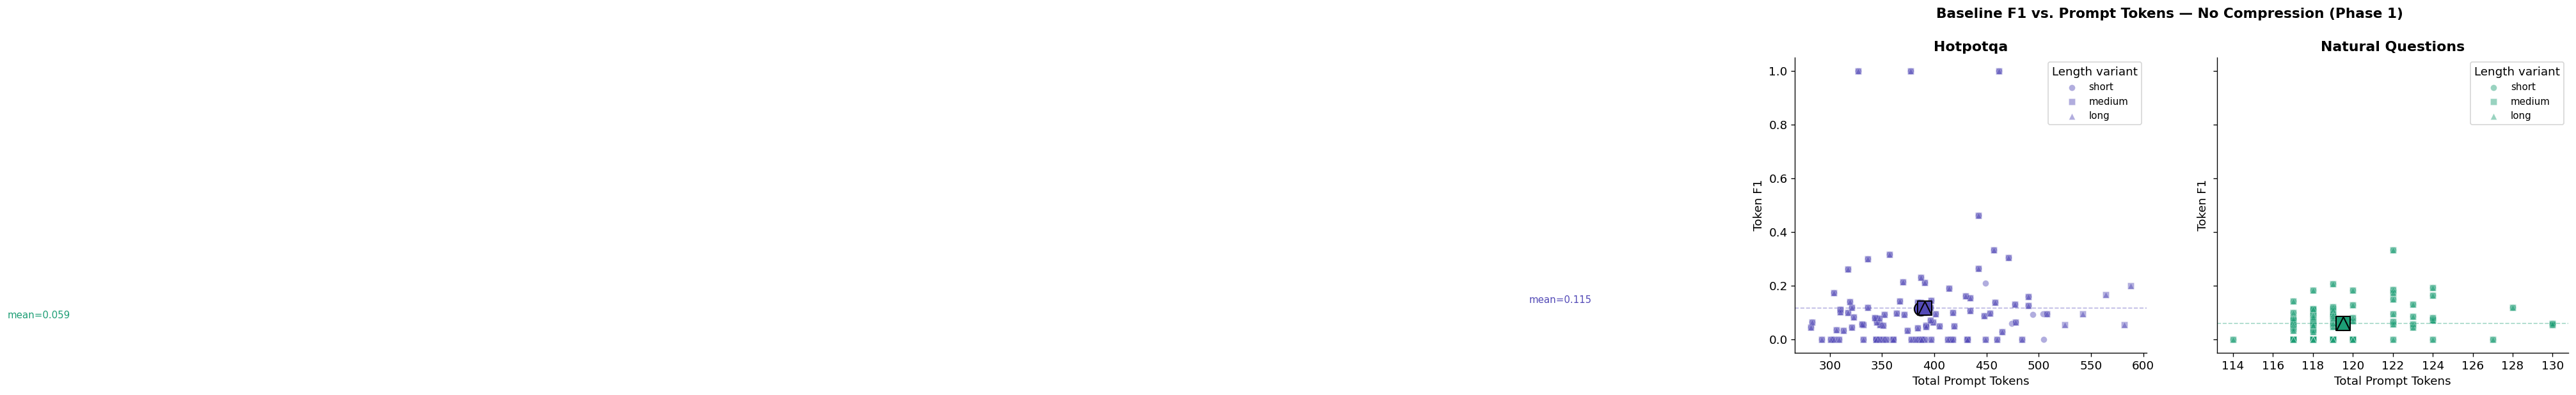

Saved plot1_f1_vs_tokens.png


In [19]:
# ── Plot 1: F1 vs Token count (scatter) per dataset
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, dataset in zip(axes, ['hotpotqa', 'natural_questions']):
    subset = df_results[df_results['dataset'] == dataset]

    for length in L_ORDER:
        lsubset = subset[subset['length_variant'] == length]
        ax.scatter(
            lsubset['total_tokens'], lsubset['f1'],
            alpha=0.45, s=35,
            marker=L_STYLES[length],
            color=PALETTE[dataset],
            label=f'{length}',
            edgecolors='white', linewidths=0.3
        )
        # Mean point (larger)
        ax.scatter(
            lsubset['total_tokens'].mean(), lsubset['f1'].mean(),
            s=160, marker=L_STYLES[length],
            color=PALETTE[dataset], zorder=5,
            edgecolors='black', linewidths=1.2
        )

    ax.set_xlabel('Total Prompt Tokens', fontsize=11)
    ax.set_ylabel('Token F1', fontsize=11)
    ax.set_title(dataset.replace('_', ' ').title(), fontweight='bold')
    ax.set_ylim(-0.05, 1.05)
    ax.legend(title='Length variant', fontsize=9)
    ax.axhline(y=subset['f1'].mean(), color=PALETTE[dataset],
               linestyle='--', alpha=0.4, linewidth=1)
    ax.text(ax.get_xlim()[1] * 0.02, subset['f1'].mean() + 0.02,
            f'mean={subset["f1"].mean():.3f}', color=PALETTE[dataset], fontsize=9)

fig.suptitle('Baseline F1 vs. Prompt Tokens — No Compression (Phase 1)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plot1_f1_vs_tokens.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved plot1_f1_vs_tokens.png')

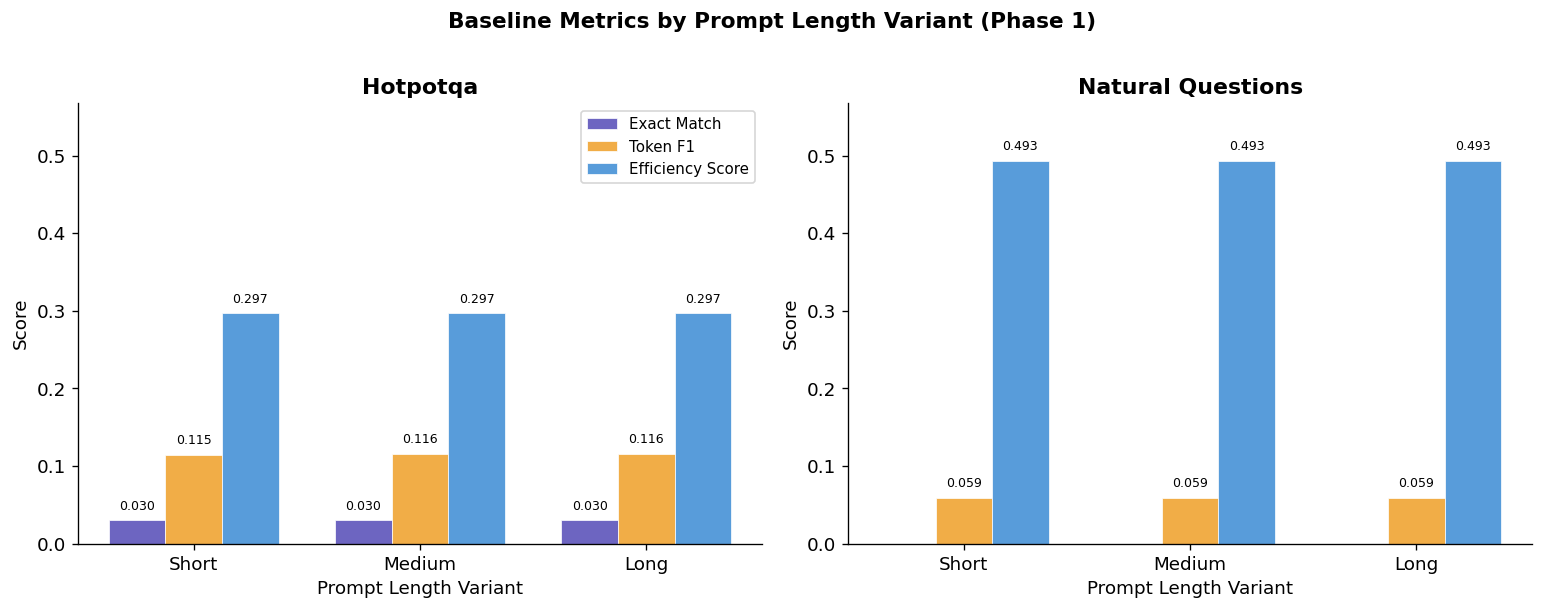

Saved plot2_grouped_bars.png


In [20]:
# ── Plot 2: Grouped bar — EM + F1 by length variant, per dataset
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics_to_plot = ['em', 'f1', 'efficiency_score']
metric_labels   = ['Exact Match', 'Token F1', 'Efficiency Score']
x = np.arange(len(L_ORDER))
bar_w = 0.25

for ax_idx, (ax, dataset) in enumerate(zip(axes, ['hotpotqa', 'natural_questions'])):
    subset = summary[summary['dataset'] == dataset].set_index('length_variant').reindex(L_ORDER)

    for i, (metric, label) in enumerate(zip(metrics_to_plot, metric_labels)):
        offset = (i - 1) * bar_w
        bars = ax.bar(
            x + offset, subset[metric].fillna(0),
            width=bar_w, label=label,
            color=[PALETTE[dataset], '#EF9F27', '#3B8BD4'][i],
            alpha=0.85, edgecolor='white', linewidth=0.5
        )
        # Value labels
        for bar in bars:
            h = bar.get_height()
            if h > 0.01:
                ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                        f'{h:.3f}', ha='center', va='bottom', fontsize=7.5)

    ax.set_xticks(x)
    ax.set_xticklabels([l.title() for l in L_ORDER])
    ax.set_xlabel('Prompt Length Variant')
    ax.set_ylabel('Score')
    ax.set_ylim(0, max(0.15, summary[metrics_to_plot].max().max() * 1.15))
    ax.set_title(dataset.replace('_', ' ').title(), fontweight='bold')
    if ax_idx == 0:
        ax.legend(fontsize=9)

fig.suptitle('Baseline Metrics by Prompt Length Variant (Phase 1)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plot2_grouped_bars.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved plot2_grouped_bars.png')

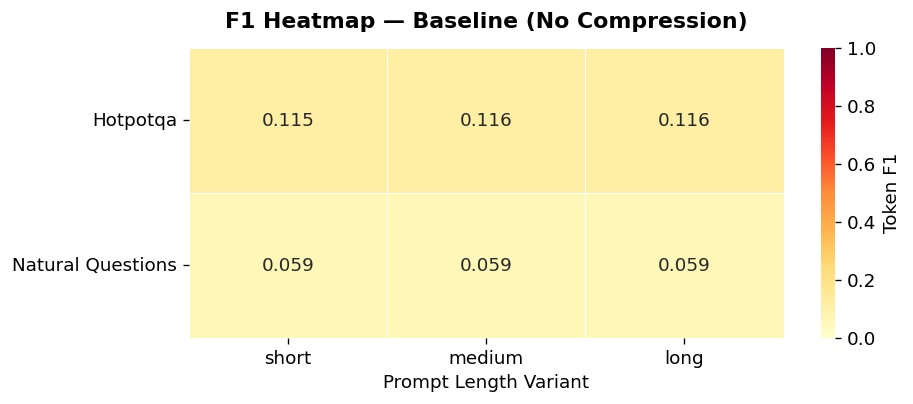

Saved plot3_f1_heatmap.png


In [21]:
# ── Plot 3: Heatmap — F1 score across dataset × length_variant
pivot = summary.pivot(index='dataset', columns='length_variant', values='f1')[L_ORDER]

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(
    pivot.astype(float), annot=True, fmt='.3f',
    cmap='YlOrRd', ax=ax, linewidths=0.5,
    cbar_kws={'label': 'Token F1'},
    vmin=0, vmax=1
)
ax.set_title('F1 Heatmap — Baseline (No Compression)', fontweight='bold', pad=12)
ax.set_xlabel('Prompt Length Variant')
ax.set_ylabel('')
ax.set_yticklabels([l.replace('_', ' ').title() for l in pivot.index], rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plot3_f1_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved plot3_f1_heatmap.png')

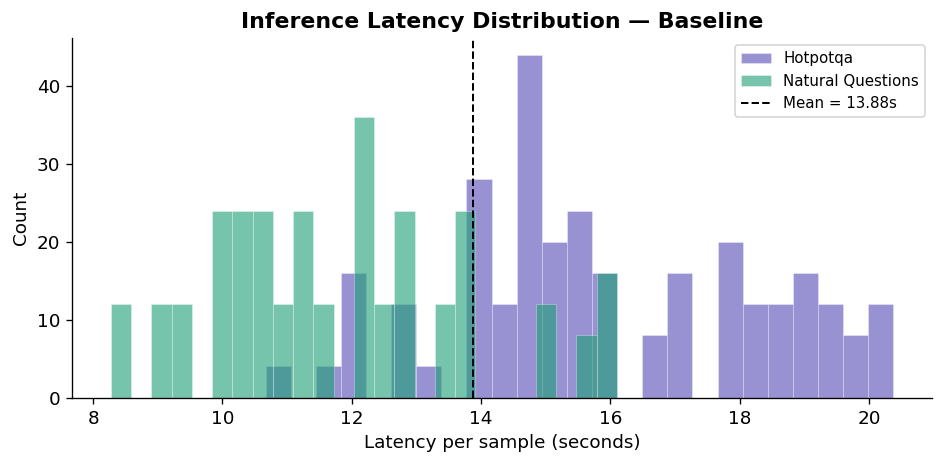

Saved plot4_latency.png


In [22]:
# ── Plot 4: Latency distribution
fig, ax = plt.subplots(figsize=(8, 4))

for dataset, color in PALETTE.items():
    subset = df_results[df_results['dataset'] == dataset]
    ax.hist(subset['latency_s'], bins=25, alpha=0.6, color=color,
            label=dataset.replace('_', ' ').title(), edgecolor='white', linewidth=0.3)

ax.axvline(df_results['latency_s'].mean(), color='black', linestyle='--', linewidth=1.2,
           label=f'Mean = {df_results["latency_s"].mean():.2f}s')
ax.set_xlabel('Latency per sample (seconds)')
ax.set_ylabel('Count')
ax.set_title('Inference Latency Distribution — Baseline', fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plot4_latency.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved plot4_latency.png')

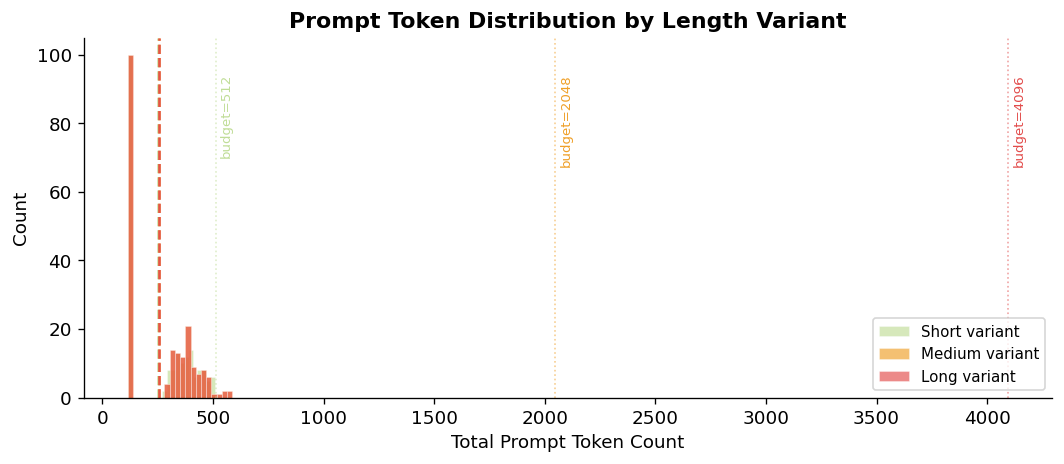

Saved plot5_token_dist.png


In [23]:
# ── Plot 5: Token count distribution by length variant
fig, ax = plt.subplots(figsize=(9, 4))

colors_len = {'short': '#C0DD97', 'medium': '#EF9F27', 'long': '#E24B4A'}

for length in L_ORDER:
    subset = df_results[df_results['length_variant'] == length]
    ax.hist(subset['total_tokens'], bins=20, alpha=0.65,
            color=colors_len[length], label=f'{length.title()} variant',
            edgecolor='white', linewidth=0.3)
    ax.axvline(subset['total_tokens'].mean(), color=colors_len[length],
               linestyle='--', linewidth=1.5, alpha=0.9)

# Mark the target budgets
for length, budget in CFG.prompt_lengths.items():
    ax.axvline(budget, color=colors_len[length], linestyle=':', linewidth=1,
               alpha=0.5)
    ax.text(budget + 20, ax.get_ylim()[1] * 0.9, f'budget={budget}',
            color=colors_len[length], fontsize=8, rotation=90, va='top')

ax.set_xlabel('Total Prompt Token Count')
ax.set_ylabel('Count')
ax.set_title('Prompt Token Distribution by Length Variant', fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plot5_token_dist.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved plot5_token_dist.png')

## 10. Token Budget Analysis for Phase 2

In [24]:
# ── Analyse what fraction of context is used at each budget
# This tells us how aggressive Phase 2 compression needs to be
# to hit meaningful token reduction targets.

print('Token Budget Analysis')
print('='*65)
print(f'{"Dataset":<22} {"Variant":<10} {"Avg Total":<12} {"Avg Context":<14} {"% Truncated"}')
print('-'*65)

target_reductions = {}

for _, row in summary.iterrows():
    budget = CFG.prompt_lengths[row['length_variant']]
    used   = row['avg_total_tokens']
    pct_t  = row['pct_truncated'] * 100

    # Potential savings if we compress to 50% context retention
    ctx_tokens = row['avg_context_tok']
    potential_saving = ctx_tokens * 0.5  # 50% context reduction target
    target_reductions[(row['dataset'], row['length_variant'])] = potential_saving

    print(f"{row['dataset']:<22} {row['length_variant']:<10} "
          f"{int(used):<12} {int(ctx_tokens):<14} "
          f"{pct_t:.1f}%")

print('='*65)
print()

# How many tokens could Phase 2 save?
avg_saving_pct = (
    df_results.groupby('length_variant').apply(
        lambda g: (g['context_tokens'] * 0.5 / g['total_tokens']).mean()
    ) * 100
)
print('Estimated token savings from 50% context compression (Phase 2 target):')
for variant, saving in avg_saving_pct.items():
    print(f'  {variant:10}: ~{saving:.1f}% total prompt reduction')

print()
print('Phase 2 will target 30–70% context compression while measuring F1 degradation.')
print('AHCC must keep F1 degradation < 3 percentage points vs this baseline.')

Token Budget Analysis
Dataset                Variant    Avg Total    Avg Context    % Truncated
-----------------------------------------------------------------
hotpotqa               short      387          316            5.0%
hotpotqa               medium     390          320            0.0%
hotpotqa               long       390          320            0.0%
natural_questions      short      119          61             0.0%
natural_questions      medium     119          61             0.0%
natural_questions      long       119          61             0.0%

Estimated token savings from 50% context compression (Phase 2 target):
  long      : ~33.3% total prompt reduction
  medium    : ~33.3% total prompt reduction
  short     : ~33.2% total prompt reduction

Phase 2 will target 30–70% context compression while measuring F1 degradation.
AHCC must keep F1 degradation < 3 percentage points vs this baseline.


## 11. Save Artifacts for Phase 2

In [25]:
# ── Save everything Phase 2 needs to continue from

# 1. Full results dataframe
df_results.to_parquet(OUTPUT_DIR / 'phase1_results_full.parquet', index=False)

# 2. Prompt bank (all samples, all variants)
df_prompts_save = df_prompts.copy()
df_prompts_save['answers'] = df_prompts_save['answers'].apply(json.dumps)
df_prompts_save.to_parquet(OUTPUT_DIR / 'prompt_bank.parquet', index=False)

# 3. Summary metrics
summary.to_csv(OUTPUT_DIR / 'phase1_baseline_results.csv', index=False)

# 4. Raw samples as JSON (for AHCC label generation in Phase 3)
samples_export = []
for s in all_samples:
    sents = chunker.chunk_sample(s)
    retrieved = retriever.retrieve(s.question, sents)
    samples_export.append({
        'sample_id':    s.sample_id,
        'dataset':      s.dataset,
        'question':     s.question,
        'answers':      s.answers,
        'difficulty':   getattr(s, 'difficulty', 'medium'),
        'sentences':    retrieved,
    })

with open(OUTPUT_DIR / 'samples_with_sentences.json', 'w') as f:
    json.dump(samples_export, f, indent=2)

# 5. Config snapshot
config_dict = {
    'llm_model_id':       CFG.llm_model_id,
    'llm_load_in_4bit':   CFG.llm_load_in_4bit,
    'bm25_top_k':         CFG.bm25_top_k,
    'prompt_lengths':     CFG.prompt_lengths,
    'hotpotqa_n':         CFG.hotpotqa_n_samples,
    'nq_n':               CFG.nq_n_samples,
    'eval_sample_size':   CFG.eval_sample_size,
    'phase1_baseline_em': float(df_results['em'].mean()),
    'phase1_baseline_f1': float(df_results['f1'].mean()),
    'phase1_avg_tokens':  float(df_results['total_tokens'].mean()),
}
with open(OUTPUT_DIR / 'phase1_config.json', 'w') as f:
    json.dump(config_dict, f, indent=2)

print('Artifacts saved to', OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.iterdir()):
    size = p.stat().st_size / 1024
    print(f'  {p.name:<45} {size:>8.1f} KB')

Artifacts saved to /kaggle/working/apol_phase1
  phase1_baseline_results.csv                        0.5 KB
  phase1_config.json                                 0.4 KB
  phase1_results_full.parquet                      180.5 KB
  plot1_f1_vs_tokens.png                           118.1 KB
  plot2_grouped_bars.png                            58.9 KB
  plot3_f1_heatmap.png                              39.8 KB
  plot4_latency.png                                 40.9 KB
  plot5_token_dist.png                              61.5 KB
  prompt_bank.parquet                              259.5 KB
  samples_with_sentences.json                     1058.3 KB


## 12. Phase 1 Summary

In [26]:
# ── Final summary printout
print('=' * 70)
print('  APOL-BENCH PHASE 1 — COMPLETE')
print('=' * 70)
print()
print('  DATASETS')
print(f'    HotpotQA samples:        {len(hotpotqa_samples)}')
print(f'    Natural Questions:        {len(nq_samples)}')
print(f'    Total samples:            {len(all_samples)}')
print()
print('  PIPELINE')
print(f'    Chunker:                  spaCy en_core_web_sm')
print(f'    Retriever:                BM25Okapi (top-{CFG.bm25_top_k})')
print(f'    LLM:                      {CFG.llm_model_id}')
print(f'    Quantization:             {"4-bit NF4" if CFG.llm_load_in_4bit else "fp16"}')
print()
print('  BASELINE METRICS (No Compression)')
print(f'    Exact Match:              {df_results["em"].mean():.4f}')
print(f'    Token F1:                 {df_results["f1"].mean():.4f}')
print(f'    Efficiency Score:         {df_results["efficiency_score"].mean():.4f}')
print(f'    Avg prompt tokens:        {df_results["total_tokens"].mean():.0f}')
print(f'    Avg latency per sample:   {df_results["latency_s"].mean():.2f}s')
print()
print('  TARGET FOR PHASE 2 (Compression Modules)')
print(f'    Token reduction target:   30–70%')
print(f'    Max F1 degradation:       ±3 percentage points')
print(f'    Methods to implement:     BM25 hard pruning, T5-small soft compression')
print()
print('  ARTIFACTS')
print(f'    Results:   {OUTPUT_DIR}/phase1_results_full.parquet')
print(f'    Prompts:   {OUTPUT_DIR}/prompt_bank.parquet')
print(f'    Samples:   {OUTPUT_DIR}/samples_with_sentences.json')
print(f'    Config:    {OUTPUT_DIR}/phase1_config.json')
print(f'    Plots:     {OUTPUT_DIR}/plot*.png')
print()
print('  PHASE 2 STARTS FROM: prompt_bank.parquet + samples_with_sentences.json')
print('=' * 70)

  APOL-BENCH PHASE 1 — COMPLETE

  DATASETS
    HotpotQA samples:        200
    Natural Questions:        200
    Total samples:            400

  PIPELINE
    Chunker:                  spaCy en_core_web_sm
    Retriever:                BM25Okapi (top-10)
    LLM:                      mistralai/Mistral-7B-Instruct-v0.2
    Quantization:             4-bit NF4

  BASELINE METRICS (No Compression)
    Exact Match:              0.0150
    Token F1:                 0.0873
    Efficiency Score:         0.3951
    Avg prompt tokens:        255
    Avg latency per sample:   13.88s

  TARGET FOR PHASE 2 (Compression Modules)
    Token reduction target:   30–70%
    Max F1 degradation:       ±3 percentage points
    Methods to implement:     BM25 hard pruning, T5-small soft compression

  ARTIFACTS
    Results:   /kaggle/working/apol_phase1/phase1_results_full.parquet
    Prompts:   /kaggle/working/apol_phase1/prompt_bank.parquet
    Samples:   /kaggle/working/apol_phase1/samples_with_sentences

In [27]:
import shutil

# Create a zip file of the entire working/output directory
shutil.make_archive('/kaggle/working/output', 'zip', '/kaggle/working')

print("Zip file created at /kaggle/working/output.zip")

Zip file created at /kaggle/working/output.zip
